# ANN vs. linear models

This notebook compares the ANN with fixed mappings from kinematics to heading: linear and circular regressions on the direction of groundspeed, airspeed and thrust.

1. **Heading vs. kinematic direction.** Heading is plotted against the direction of groundspeed, airspeed and thrust, with the best free-slope circular (Möbius) regression overlaid.
2. **Flight regimes.** The same relationship is split into upwind, crosswind and downwind flight, and a fit made within each regime is compared with the global fit.
3. **Tables.** Every baseline (14 linear/circular OLS models and three Möbius models) is compared with the ANN on the same held-out trajectories, by regime, along with leave-one-wind-speed-out, robustness, model-selection, calibration and covariate tables.
4. **Paired comparison.** Per-trajectory comparisons of the ANN with the best baselines in each regime.

**Inputs.** The corrected data from `01_data_correction_and_processing.ipynb` and the ANN results written by `02_training_and_testing_the_ann.ipynb`. Baselines are fit here on the training trajectories of the same trajectory-grouped split (seed 42, 33% test) used to train the ANN, so ANN and baselines are scored on identical held-out trajectories. A consistency check below stops the notebook if the saved ANN results come from a different split.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from scipy.optimize import minimize
from scipy.stats import spearmanr, wilcoxon
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display
sys.path.insert(0, os.path.abspath('../utils'))
from utils import circular_distance, make_color_map

# corrected, training-ready data (written by 01_data_correction_and_processing.ipynb)
DATA_PATH = '../trainingdata/04_trainingdata/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv'
# ANN results (written by 02_training_and_testing_the_ann.ipynb)
RESULTS = '../tables/'
STRICT_SPLIT_CHECK = True   # stop if the saved ANN results were produced on a different train/test split

pd.set_option('display.width', 200); pd.set_option('display.max_columns', None)
TWO_PI = 2 * np.pi
REGIMES = ['upwind', 'crosswind', 'downwind']
THRESH = 15.0
os.makedirs('../figures', exist_ok=True)

/Users/florisvb/src/drosophila_body_orientation_predictor/.venv/lib/python3.12/site-packages/pynumdiff/__init__.py:9: UserWarning: tvrdiff, robustdiff, and lineardiff not available due to lack of convex solver. To use those, install CVXPY.
  warn("tvrdiff, robustdiff, and lineardiff not available due to lack of convex solver. To use those, install CVXPY.")


## Data and split

In [2]:
data = pd.read_csv(DATA_PATH)
ids = data['trajec_objid'].unique()
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.33, random_state=42).split(np.zeros((len(ids), 1)), groups=ids))
train_ids, test_ids = set(ids[tr]), set(ids[te])
train_df = data[data['trajec_objid'].isin(train_ids)].reset_index(drop=True)
test_df  = data[data['trajec_objid'].isin(test_ids)].reset_index(drop=True)
print(f'{len(ids)} trajectories, {len(data)} frames | train {len(train_ids)} / test {len(test_ids)} trajectories')

# the ANN results must come from this exact split
ann_frames = pd.read_csv(RESULTS + 'ann_by_regime.csv')
not_in_test = set(ann_frames['trajec_objid']) - test_ids
print(f'ANN held-out trajectories: {ann_frames["trajec_objid"].nunique()} | not in this notebook\'s test set: {len(not_in_test)}')
if not_in_test:
    msg = (f'{len(not_in_test)} of the ANN\'s held-out trajectories are not in this split: the saved ANN results come from different data '
           f'or a different split. Re-run 02_training_and_testing_the_ann.ipynb on the current data first.')
    if STRICT_SPLIT_CHECK: raise AssertionError(msg)
    print('WARNING:', msg)

3321 trajectories, 112083 frames | train 2225 / test 1096 trajectories
ANN held-out trajectories: 1096 | not in this notebook's test set: 0


## 1. Heading vs. kinematic direction

Heading against the direction of groundspeed, airspeed and thrust (log-count heatmaps), with a **free-slope circular regression** (Möbius / Downs–Mardia), $\hat\theta = \mu + 2\arctan(\beta\tan\frac{\theta_x-\nu}{2})$, fit by minimising $\sum(1-\cos e)$. Circular $R^2 = 1 - \sum(1-\cos e_i)/\sum(1-\cos(\theta_{h,i}-\bar\theta_h))$. Fits here use all frames and are in-sample; held-out evaluation is in the tables below.

In [3]:
def circ_mean(a): return np.arctan2(np.sin(a).mean(), np.cos(a).mean())
def mobius(x, mu, nu, lb): return mu + 2 * np.arctan(np.exp(lb) * np.tan((x - nu) / 2))

def fit_mobius(x, y):
    best = None
    for nu0 in np.linspace(0, TWO_PI, 8, endpoint=False):
        for lb0 in (-1.0, 0.0, 1.0, 2.0):
            r = minimize(lambda p: np.mean(1 - np.cos(y - mobius(x, *p))), [circ_mean(y - x), nu0, lb0],
                         method='Nelder-Mead', options=dict(xatol=1e-6, fatol=1e-10, maxiter=4000))
            if best is None or r.fun < best.fun: best = r
    return best.x

def circular_r2(y, yhat):
    return 1 - np.sum(1 - np.cos(y - yhat)) / np.sum(1 - np.cos(y - circ_mean(y)))

heading = data['heading_angle'].values % TWO_PI
predictors = [('Groundspeed direction (rad)', 'groundspeed_angle'),
              ('Airspeed direction (rad)', 'airspeed_angle'),
              ('Thrust direction (rad)', 'thrust_angle')]
x_wrapped = {col: data[col].values % TWO_PI for _, col in predictors}
fits = {}
for name, col in predictors:
    p = fit_mobius(x_wrapped[col], heading)
    fits[col] = (p, circular_r2(heading, mobius(x_wrapped[col], *p)))
    print(f'{name}: mu={p[0] % TWO_PI:.3f} nu={p[1] % TWO_PI:.3f} beta={np.exp(p[2]):.2f} circular R^2={fits[col][1]:.3f}')

Groundspeed direction (rad): mu=6.270 nu=0.009 beta=3.29 circular R^2=0.221


Airspeed direction (rad): mu=0.100 nu=0.073 beta=0.60 circular R^2=0.570


Thrust direction (rad): mu=0.283 nu=0.258 beta=0.76 circular R^2=0.495


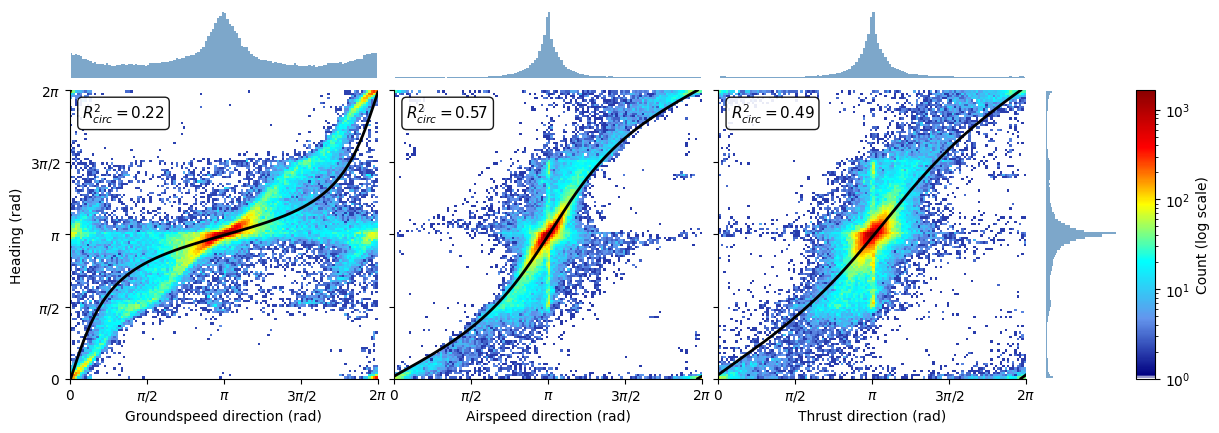

In [4]:
cmap = make_color_map(color_list=['white', 'navy', 'cornflowerblue', 'aqua', 'yellow', 'red', 'darkred'], N=256)
PI_TICKS  = [0, np.pi/2, np.pi, 3*np.pi/2, TWO_PI]
PI_LABELS = [r'$0$', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$']
N_BINS = 128

def heatmap(ax, x, y, show_ylabel=True):
    h, xe, ye = np.histogram2d(x, y, bins=N_BINS, range=[[0, TWO_PI]] * 2)
    im = ax.pcolormesh(xe, ye, np.ma.masked_where(h.T == 0, h.T), norm=mcolors.LogNorm(vmin=1, vmax=max(h.max(), 2)),
                       cmap=cmap, rasterized=True)
    ax.set_xlim(0, TWO_PI); ax.set_ylim(0, TWO_PI)
    ax.set_xticks(PI_TICKS); ax.set_xticklabels(PI_LABELS)
    ax.set_yticks(PI_TICKS); ax.set_yticklabels(PI_LABELS if show_ylabel else [''] * 5)
    if show_ylabel: ax.set_ylabel('Heading (rad)', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
    return im

def regression_line(ax, params, label=None, **kw):
    xs = np.linspace(0, TWO_PI, 2000)
    ys = mobius(xs, *params) % TWO_PI
    ys[np.r_[False, np.abs(np.diff(ys)) > np.pi]] = np.nan   # break the line at the 2pi seam
    ax.plot(xs, ys, label=label, **kw)

fig = plt.figure(figsize=(14, 4.8))
gs = gridspec.GridSpec(2, 5, figure=fig, width_ratios=[4, 4, 4, 1, 0.25], height_ratios=[1, 4], hspace=0.05, wspace=0.08)
for i, (name, col) in enumerate(predictors):
    x = x_wrapped[col]; params, r2 = fits[col]
    ax_top, ax_main = fig.add_subplot(gs[0, i]), fig.add_subplot(gs[1, i])
    im = heatmap(ax_main, x, heading, show_ylabel=(i == 0))
    regression_line(ax_main, params, color='black', lw=2)
    ax_main.text(0.04, 0.96, rf'$R^2_{{circ}} = {r2:.2f}$', transform=ax_main.transAxes, va='top',
                 bbox=dict(boxstyle='round', fc='white', ec='black', alpha=0.9), fontsize=11)
    ax_main.set_xlabel(name, fontsize=10)
    counts, edges = np.histogram(x, bins=N_BINS, range=(0, TWO_PI))
    ax_top.fill_between(0.5 * (edges[:-1] + edges[1:]), counts, step='mid', color='steelblue', alpha=0.7, lw=0)
    ax_top.set_xlim(0, TWO_PI); ax_top.set_xticks([]); ax_top.set_yticks([])
    for s in ax_top.spines.values(): s.set_visible(False)
ax_right = fig.add_subplot(gs[1, 3])
counts, edges = np.histogram(heading, bins=N_BINS, range=(0, TWO_PI))
ax_right.fill_betweenx(0.5 * (edges[:-1] + edges[1:]), counts, step='mid', color='steelblue', alpha=0.7, lw=0)
ax_right.set_ylim(0, TWO_PI); ax_right.set_xticks([]); ax_right.set_yticks([])
for s in ax_right.spines.values(): s.set_visible(False)
cbar = fig.colorbar(im, cax=fig.add_subplot(gs[1, 4]), label='Count (log scale)'); cbar.ax.yaxis.label.set_size(10)
fig.savefig('../figures/ann_vs_linear_models_heatmaps.pdf', bbox_inches='tight')
fig.savefig('../figures/ann_vs_linear_models_heatmaps.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Flight regimes

Each frame is assigned to a regime from the true heading relative to the wind axis (the wind blows toward +x, so upwind is −x): **downwind** $|\theta|\le45^\circ$, **upwind** within $45^\circ$ of $180^\circ$, **crosswind** otherwise. A trajectory contributes to every regime it visits. The global fit is compared with a fit made within each regime.

In [5]:
def classify_direction(a):
    deg = np.degrees(np.arctan2(np.sin(a), np.cos(a)))
    return np.where(np.abs(deg) <= 45, 'downwind', np.where(np.abs(np.abs(deg) - 180) <= 45, 'upwind', 'crosswind'))

data['regime'] = classify_direction(data['heading_angle'].values)
cnt = data.groupby('regime').agg(frames=('regime', 'size'), trajectories=('trajec_objid', 'nunique')).reindex(REGIMES)
cnt['% of frames'] = (100 * cnt['frames'] / len(data)).round(1)
display(cnt)

,frames,trajectories,% of frames
regime,,,
upwind,75885,2704,67.7
crosswind,26530,1895,23.7
downwind,9668,760,8.6


In [6]:
airspeed_x = data['airspeed_angle'].values % TWO_PI
global_params, _ = fits['airspeed_angle']
rows, regime_fit = [], {}
for reg in REGIMES:
    m = (data['regime'] == reg).values
    x, y = airspeed_x[m], heading[m]
    p_reg = fit_mobius(x, y); regime_fit[reg] = p_reg
    r2_glob = circular_r2(y, mobius(x, *global_params)); r2_reg = circular_r2(y, mobius(x, *p_reg))
    rows.append({'regime': reg, 'frames': int(m.sum()), 'beta (within regime)': np.exp(p_reg[2]), 'nu (within regime)': p_reg[1] % TWO_PI,
                 'mu (within regime)': p_reg[0] % TWO_PI, 'circular R2, global fit': r2_glob, 'circular R2, within-regime fit': r2_reg})
gp = global_params
print(f'global fit: beta={np.exp(gp[2]):.2f}  nu={gp[1] % TWO_PI:.3f}  mu={gp[0] % TWO_PI:.3f}')
display(pd.DataFrame(rows).round(3))

global fit: beta=0.60  nu=0.073  mu=0.100


,regime,frames,beta (within regime),nu (within regime),mu (within regime),"circular R2, global fit","circular R2, within-regime fit"
0,upwind,75885,265.085,1.952,6.279,-1.107,0.002
1,crosswind,26530,0.420,0.143,0.193,0.576,0.607
2,downwind,9668,0.002,0.453,0.005,-3.907,0.009


## 3. Tables

### Setup: baselines on the held-out split

*Linear* OLS regresses the heading unit vector on the Cartesian components of each kinematic vector; *circular* OLS regresses it on the unit direction only; *Möbius* is the free-slope circular regression above, fit on the training trajectories, one input angle at a time. All 14 OLS/circular baselines (thrust, airspeed, groundspeed and every combination, in both forms) and the three Möbius models are fit on the training trajectories and scored on the held-out trajectories, per trajectory (median over its frames), exactly as for the ANN. From here on, regimes are assigned by course direction (`groundspeed_angle`, the direction of travel, known at inference time), not by the true heading as in Section 2.

In [7]:
from itertools import combinations
QUANT = {'thrust': ('thrust', 'thrust_angle'), 'air': ('airspeed', 'airspeed_angle'), 'ground': ('groundspeed', 'groundspeed_angle')}

def design(d, combo, kind):
    cols = [np.ones(len(d))]
    for q in combo:
        m, a = QUANT[q]
        if kind == 'linear': cols += [d[m].values * np.cos(d[a].values), d[m].values * np.sin(d[a].values)]
        else:                cols += [np.cos(d[a].values), np.sin(d[a].values)]
    return np.column_stack(cols)

def ols_angle(train, test, combo, kind):
    coef = np.linalg.lstsq(design(train, combo, kind), train[['heading_angle_x', 'heading_angle_y']].values, rcond=None)[0]
    p = design(test, combo, kind) @ coef
    return np.arctan2(p[:, 1], p[:, 0])

def mobius_angle(train, test, q):
    a = QUANT[q][1]
    return mobius(test[a].values, *fit_mobius(train[a].values, train['heading_angle'].values))

def frame_errors(test, pred_angle):
    err = np.degrees(circular_distance(test['heading_angle'].values, pred_angle))
    return pd.DataFrame({'trajec_objid': test['trajec_objid'].values, 'err': err, 'regime': classify_direction(test['groundspeed_angle'].values)})

def summarize(fdf):
    '''per-trajectory medians: pooled over all frames, and within each regime'''
    pooled = fdf.groupby('trajec_objid')['err'].median()
    by_reg = fdf.groupby(['regime', 'trajec_objid'])['err'].median().reset_index()
    s = {'overall': pooled.median()}
    for r in REGIMES: s[r] = by_reg.loc[by_reg['regime'] == r, 'err'].median()
    return s, pooled, by_reg

FAMILY = {'linear': 'Linear OLS', 'circular': 'Circular OLS', 'mobius': 'Möbius circular regression', 'ANN': 'ANN'}
res = {}
for r_ in range(1, 4):
    for combo in combinations(QUANT, r_):
        for kind in ('linear', 'circular'):
            s, pooled, by_reg = summarize(frame_errors(test_df, ols_angle(train_df, test_df, combo, kind)))
            res[f'{kind}: {"+".join(combo)}'] = dict(s=s, pooled=pooled, by_reg=by_reg, family=kind, inputs='+'.join(combo))
for q in QUANT:
    s, pooled, by_reg = summarize(frame_errors(test_df, mobius_angle(train_df, test_df, q)))
    res[f'mobius: {q}'] = dict(s=s, pooled=pooled, by_reg=by_reg, family='mobius', inputs=q)
ann_s, ann_pooled, ann_by_reg = summarize(ann_frames)
res['ANN'] = dict(s=ann_s, pooled=ann_pooled, by_reg=ann_by_reg, family='ANN', inputs='groundspeed + airspeed')
print(len(res) - 1, 'baselines +', 'ANN')

def best(family):
    c = {k: v for k, v in res.items() if v['family'] == family}
    return min(c, key=lambda k: c[k]['s']['overall'])
BEST = {fam: best(fam) for fam in ('linear', 'circular', 'mobius')}
print('best by pooled median error:', BEST)

def bootstrap_ci(v, n_boot=5000, seed=0):
    v = np.asarray(v); rng = np.random.default_rng(seed)
    med = np.median(rng.choice(v, size=(n_boot, len(v)), replace=True), axis=1)
    lo, hi = np.percentile(med, [2.5, 97.5]); return float(np.median(v)), float(lo), float(hi)
def ci_str(m, lo, hi): return f'{m:.2f} [{lo:.2f}, {hi:.2f}]'

17 baselines + ANN
best by pooled median error: {'linear': 'linear: thrust+ground', 'circular': 'circular: thrust+air+ground', 'mobius': 'mobius: air'}


In [8]:
# Save the OLS baselines and per-trajectory errors; 04_generate_tables.ipynb reads these.
ols = {k: v for k, v in res.items() if v['family'] in ('linear', 'circular')}
(pd.DataFrame([{'model': k, **v['s']} for k, v in ols.items()])
   .sort_values('overall').reset_index(drop=True)
   .to_csv(RESULTS + 'ols_baselines_by_regime.csv', index=False))
(pd.concat([pd.DataFrame({'model': k, 'trajec_objid': v['pooled'].index, 'err': v['pooled'].values})
            for k, v in res.items() if v['family'] != 'mobius'], ignore_index=True)
   .to_csv(RESULTS + 'trajectory_level_errors_all_models.csv', index=False))


### Table 1 — Every baseline and the ANN, by flight regime

Median per-trajectory angular error (deg) on the held-out test trajectories.

In [9]:
t1 = pd.DataFrame([{'Model': FAMILY[v['family']], 'Inputs': v['inputs'], **{c.capitalize(): v['s'][c] for c in ['overall'] + REGIMES}} for v in res.values()])
t1 = t1.sort_values('Overall', ascending=False).reset_index(drop=True)
nonann = t1[t1['Model'] != 'ANN']
print('best non-ANN baseline per column:', {c: (nonann.loc[nonann[c].idxmin(), 'Model'] + ': ' + nonann.loc[nonann[c].idxmin(), 'Inputs'], round(nonann[c].min(), 2)) for c in ['Overall'] + [r.capitalize() for r in REGIMES]})
table1 = t1.copy()
for c in ['Overall'] + [r.capitalize() for r in REGIMES]: table1[c] = table1[c].map('{:.2f}'.format)
display(table1)

best non-ANN baseline per column: {'Overall': ('Möbius circular regression: air', 8.4), 'Upwind': ('Linear OLS: air+ground', 3.96), 'Crosswind': ('Möbius circular regression: air', 13.64), 'Downwind': ('Circular OLS: thrust+air+ground', 24.47)}


,Model,Inputs,Overall,Upwind,Crosswind,Downwind
0,Circular OLS,ground,16.81,4.42,27.90,73.61
1,Möbius circular regression,ground,15.78,5.03,31.43,61.25
2,Möbius circular regression,thrust,14.85,9.48,21.35,31.96
3,Linear OLS,thrust,14.84,7.60,23.14,38.64
4,Circular OLS,thrust,13.46,7.12,25.53,32.05
5,Linear OLS,ground,11.08,4.08,20.48,40.47
6,Circular OLS,thrust+ground,10.92,4.63,21.20,29.75
7,Linear OLS,air+ground,10.39,3.96,19.48,37.32
8,Linear OLS,air,10.20,4.34,18.80,38.03
9,Circular OLS,air,9.83,4.55,24.14,25.54


### Table 2 — Per-trajectory error distribution, all models

Median with 95% bootstrap CI (resampling trajectories), mean, interquartile range, 90th percentile and fraction of trajectories above 15°.

In [10]:
def dist_row(label, v):
    v = np.asarray(v); m, lo, hi = bootstrap_ci(v)
    return {'Model': label, 'n': len(v), 'Median [95% CI]': ci_str(m, lo, hi), 'Mean': f'{v.mean():.2f}',
            'IQR': f'{np.percentile(v, 25):.2f}–{np.percentile(v, 75):.2f}', 'Q90': f'{np.percentile(v, 90):.2f}', f'% > {THRESH:g}°': f'{100 * (v > THRESH).mean():.1f}'}
table2 = pd.DataFrame([dist_row(k, v['pooled'].values) for k, v in res.items()])
table2['_k'] = table2['Median [95% CI]'].str.split(' ').str[0].astype(float)
display(table2.sort_values('_k', ascending=False).drop(columns='_k').reset_index(drop=True))

,Model,n,Median [95% CI],Mean,IQR,Q90,% > 15°
0,circular: ground,1096,"16.81 [14.45, 20.02]",32.10,4.32–49.12,91.27,52.1
1,mobius: ground,1096,"15.78 [13.95, 18.03]",28.84,5.37–39.80,63.36,51.0
2,mobius: thrust,1096,"14.85 [13.58, 16.14]",22.06,7.73–29.43,49.46,49.8
3,linear: thrust,1096,"14.84 [13.53, 16.13]",23.82,6.87–36.01,56.27,49.7
4,circular: thrust,1096,"13.46 [12.53, 15.26]",22.32,6.43–33.19,53.42,47.5
5,linear: ground,1096,"11.08 [9.62, 13.03]",22.30,4.09–30.80,53.03,43.4
6,circular: thrust+ground,1096,"10.92 [9.72, 12.09]",19.04,4.49–26.86,46.26,41.2
7,linear: air+ground,1096,"10.39 [9.07, 11.89]",21.03,3.99–28.36,50.15,41.2
8,linear: air,1096,"10.20 [8.92, 11.50]",21.05,4.32–29.25,50.51,41.4
9,circular: air,1096,"9.83 [8.64, 10.99]",20.39,4.38–26.44,51.05,40.6


### Table 3 — ANN error by flight regime

Per-trajectory median error within each regime, with the best baseline of any kind in that regime for reference.

In [11]:
def regime_row(label, v):
    v = np.asarray(v); m, lo, hi = bootstrap_ci(v)
    return {'Regime': label, 'n trajectories': len(v), 'Median [95% CI]': ci_str(m, lo, hi), 'Mean': f'{v.mean():.2f}',
            'IQR': f'{np.percentile(v, 25):.2f}–{np.percentile(v, 75):.2f}', f'% > {THRESH:g}°': f'{100 * (v > THRESH).mean():.1f}'}
rows = [regime_row('Overall', ann_pooled.values)] + [regime_row(r.capitalize(), ann_by_reg.loc[ann_by_reg['regime'] == r, 'err']) for r in REGIMES]
table3 = pd.DataFrame(rows)
others = {k: v for k, v in res.items() if v['family'] != 'ANN'}
bb = [min(others, key=lambda k: others[k]['s'][c]) for c in ['overall'] + REGIMES]
table3['Best baseline (median)'] = [f"{others[k]['s'][c]:.2f}  ({k})" for k, c in zip(bb, ['overall'] + REGIMES)]
display(table3)

,Regime,n trajectories,Median [95% CI],Mean,IQR,% > 15°,Best baseline (median)
0,Overall,1096,"4.91 [4.40, 5.20]",15.06,2.52–12.18,21.2,8.40 (mobius: air)
1,Upwind,721,"3.20 [2.96, 3.44]",7.87,2.08–5.97,9.7,3.96 (linear: air+ground)
2,Crosswind,639,"10.70 [9.68, 11.94]",20.37,5.53–21.91,38.5,13.64 (mobius: air)
3,Downwind,459,"11.36 [9.16, 13.19]",32.72,3.81–41.38,42.9,24.47 (circular: thrust+air+ground)


### Table 4 — Leave-one-wind-speed-out

ANN: trained on two wind speeds and tested on the third (saved results). Baselines: the best linear and best circular OLS models (by pooled error above) and the airspeed Möbius regression, refit under the same leave-one-out design. Baseline errors are medians over all frames of the held-out trajectories; ANN errors use trajectories after the minimum-length filter, so counts can differ slightly.

In [12]:
lowo = pd.read_csv(RESULTS + 'leave_one_wind_out_results.csv')
def fit_predict(train, test, spec):
    kind, inputs = spec.split(': ')
    return mobius_angle(train, test, inputs) if kind == 'mobius' else ols_angle(train, test, tuple(inputs.split('+')), kind)
LOWO_BASELINES = {'Linear (best)': BEST['linear'], 'Circular (best)': BEST['circular'], 'Möbius (air)': 'mobius: air'}
rows = []
for ws in sorted(data['windspeed'].unique()):
    trn, tst = data[data['windspeed'] != ws], data[data['windspeed'] == ws].reset_index(drop=True)
    out = {lab: summarize(frame_errors(tst, fit_predict(trn, tst, spec)))[0] for lab, spec in LOWO_BASELINES.items()}
    for reg in ['overall'] + REGIMES:
        a = lowo[np.isclose(lowo['held_out_windspeed'], ws) & (lowo['regime'] == reg)].iloc[0]
        rows.append({'Held-out wind speed (m/s)': ws, 'Regime': reg.capitalize(), 'n (ANN)': int(a['n_trajectories']),
                     'ANN [95% CI]': ci_str(a['median'], a['ci95_lo'], a['ci95_hi']), **{lab: f'{out[lab][reg]:.2f}' for lab in LOWO_BASELINES}})
table4 = pd.DataFrame(rows)
print({k: v for k, v in LOWO_BASELINES.items()})
display(table4)

{'Linear (best)': 'linear: thrust+ground', 'Circular (best)': 'circular: thrust+air+ground', 'Möbius (air)': 'mobius: air'}


,Held-out wind speed (m/s),Regime,n (ANN),ANN [95% CI],Linear (best),Circular (best),Möbius (air)
0,0.3,Overall,1266,"5.81 [5.34, 6.35]",19.00,11.85,8.44
1,0.3,Upwind,750,"4.30 [4.01, 4.65]",5.04,5.34,6.93
2,0.3,Crosswind,771,"11.41 [10.45, 12.58]",26.56,24.80,12.37
3,0.3,Downwind,576,"11.56 [9.16, 13.80]",49.72,21.88,19.61
4,0.4,Overall,1060,"4.81 [4.38, 5.23]",9.65,10.10,8.34
5,0.4,Upwind,679,"3.14 [2.95, 3.32]",4.03,4.08,5.30
6,0.4,Crosswind,642,"9.91 [9.18, 11.12]",17.02,19.68,13.69
7,0.4,Downwind,422,"12.41 [9.83, 14.79]",37.12,23.91,24.13
8,0.6,Overall,995,"6.50 [6.06, 7.01]",6.82,8.89,6.97
9,0.6,Upwind,723,"3.81 [3.64, 4.04]",3.86,4.05,3.86


### Table 5 — Robustness across training seeds

In [13]:
seeds = pd.read_csv(RESULTS + 'ann_multiseed_results.csv')
t5 = pd.DataFrame({'Seed': seeds['seed'], 'Median error (deg)': seeds['median_error'].map('{:.2f}'.format), 'Mean error (deg)': seeds['mean_error'].map('{:.2f}'.format)})
tail = pd.DataFrame([{'Seed': 'mean ± sd', 'Median error (deg)': f"{seeds['median_error'].mean():.2f} ± {seeds['median_error'].std():.2f}", 'Mean error (deg)': f"{seeds['mean_error'].mean():.2f} ± {seeds['mean_error'].std():.2f}"},
                     {'Seed': 'range', 'Median error (deg)': f"{seeds['median_error'].min():.2f}–{seeds['median_error'].max():.2f}", 'Mean error (deg)': f"{seeds['mean_error'].min():.2f}–{seeds['mean_error'].max():.2f}"}])
display(pd.concat([t5, tail], ignore_index=True))

,Seed,Median error (deg),Mean error (deg)
0,42,4.91,15.06
1,7,4.96,15.16
2,13,5.90,15.76
3,99,4.99,15.05
4,123,5.21,15.35
5,mean ± sd,5.19 ± 0.41,15.28 ± 0.29
6,range,4.91–5.90,15.05–15.76


### Table 6 — Architecture selection (3-fold trajectory-grouped CV)

In [14]:
def cv_rows(df, label_fn):
    return [{'Configuration': label_fn(r), 'n': int(r['n_trajectories']), 'CV median [95% CI]': ci_str(r['cv_median_error'], r['cv_ci95_lo'], r['cv_ci95_hi']),
             'IQR': f"{r['cv_q25']:.2f}–{r['cv_q75']:.2f}"} for _, r in df.iterrows()]
arch = lambda r: f"{int(r['layers'])} × {int(r['neurons'])}"
if os.path.exists(RESULTS + 'architecture_cv_results.csv'):
    display(pd.DataFrame(cv_rows(pd.read_csv(RESULTS + 'architecture_cv_results.csv'), arch)))
else:
    print('Skipping Table 6: architecture_cv_results.csv not found (run 02_training_and_testing_the_ann.ipynb with RETRAIN = True).')

,Configuration,n,CV median [95% CI],IQR
0,3 × 30,2225,"5.15 [4.91, 5.49]",2.70–12.70
1,3 × 20,2225,"5.19 [4.91, 5.46]",2.74–13.17
2,2 × 20,2225,"5.26 [4.92, 5.61]",2.90–13.45
3,2 × 30,2225,"5.28 [4.95, 5.52]",2.77–13.20
4,3 × 15,2225,"5.33 [5.00, 5.66]",2.75–13.18
5,2 × 15,2225,"5.48 [5.24, 5.76]",3.01–13.29
6,1 × 30,2225,"5.53 [5.26, 5.84]",3.00–13.99
7,2 × 10,2225,"5.54 [5.28, 5.82]",3.10–13.91
8,3 × 10,2225,"5.55 [5.32, 5.83]",3.05–13.70
9,1 × 15,2225,"5.59 [5.25, 5.92]",2.93–14.20


### Table 7 — Ensemble-agreement calibration

In [15]:
ens = pd.read_csv(RESULTS + 'ann_ensemble_agreement.csv')
ens['quartile'] = pd.qcut(ens['R'], 4, labels=['Q1 (lowest agreement)', 'Q2', 'Q3', 'Q4 (highest agreement)'])
t7 = ens.groupby('quartile', observed=True).agg(n=('err', 'size'), median_R=('R', 'median'), median_err=('err', 'median'), mean_err=('err', 'mean')).reset_index()
t7.columns = ['Agreement quartile', 'n', 'Median R', 'Median error (deg)', 'Mean error (deg)']
t7['Median R'] = t7['Median R'].map('{:.5f}'.format)
for c in ['Median error (deg)', 'Mean error (deg)']: t7[c] = t7[c].map('{:.2f}'.format)
print(f'Spearman rho (R vs error) = {spearmanr(ens["R"], ens["err"]).statistic:.3f}')
display(t7)

Spearman rho (R vs error) = -0.543


,Agreement quartile,n,Median R,Median error (deg),Mean error (deg)
0,Q1 (lowest agreement),274,0.99817,13.13,32.19
1,Q2,274,0.99910,5.19,12.61
2,Q3,274,0.99942,3.65,7.65
3,Q4 (highest agreement),274,0.99971,2.36,7.80


### Table 8 — ANN error vs. trajectory covariates

In [16]:
cov = pd.read_csv(RESULTS + 'ann_error_with_covariates.csv')
labels = {'mean_slip_angle': 'Mean |slip angle| (deg)', 'max_turning_rate': 'Max turning rate (deg/frame)', 'mean_thrust': 'Mean thrust magnitude',
          'mean_groundspeed': 'Mean groundspeed (m/s)', 'mean_airspeed': 'Mean airspeed (m/s)', 'windspeed': 'Wind speed (m/s)'}
rows = [{'Covariate': lab, 'Spearman ρ': f'{spearmanr(cov[c], cov["err"]).statistic:.3f}', 'p': f'{spearmanr(cov[c], cov["err"]).pvalue:.1e}', 'n': len(cov)} for c, lab in labels.items()]
display(pd.DataFrame(rows).sort_values('Spearman ρ', key=lambda s: s.astype(float).abs(), ascending=False).reset_index(drop=True))

,Covariate,Spearman ρ,p,n
0,Mean |slip angle| (deg),0.731,1.6e-183,1096
1,Max turning rate (deg/frame),0.579,6.0e-99,1096
2,Mean groundspeed (m/s),-0.525,1.5e-78,1096
3,Mean airspeed (m/s),-0.507,1.5e-72,1096
4,Mean thrust magnitude,-0.472,6.7e-62,1096
5,Wind speed (m/s),-0.006,8.3e-01,1096


## 4. Paired comparison with the ANN

The ANN and the best baselines are compared trajectory by trajectory: for each held-out trajectory and regime it takes the difference *baseline error − ANN error* (positive = ANN better), summarised by the median difference with a 95% bootstrap CI over trajectories, the fraction of trajectories where the ANN is better, and a Wilcoxon signed-rank test. Compared: the best linear OLS, best circular OLS and best Möbius baseline (selected by pooled held-out error).

In [17]:
def paired(base_key):
    rows = []
    for reg in ['overall'] + REGIMES:
        if reg == 'overall': b, a = res[base_key]['pooled'], res['ANN']['pooled']
        else:
            b = res[base_key]['by_reg'].query('regime == @reg').set_index('trajec_objid')['err']
            a = res['ANN']['by_reg'].query('regime == @reg').set_index('trajec_objid')['err']
        j = pd.concat([b.rename('b'), a.rename('a')], axis=1, join='inner')
        d = (j['b'] - j['a']).values
        m, lo, hi = bootstrap_ci(d)
        rows.append({'Baseline': base_key, 'Regime': reg.capitalize(), 'n': len(d), 'Baseline median': j['b'].median(), 'ANN median': j['a'].median(),
                     'Median diff (baseline − ANN) [95% CI]': ci_str(m, lo, hi), '% trajectories ANN better': 100 * (d > 0).mean(),
                     'Wilcoxon p': wilcoxon(d).pvalue if np.any(d != 0) else np.nan, 'ANN better (CI > 0)': lo > 0})
    return rows
paired_tbl = pd.DataFrame(sum([paired(k) for k in BEST.values()], []))
display(paired_tbl.round(3))

,Baseline,Regime,n,Baseline median,ANN median,Median diff (baseline − ANN) [95% CI],% trajectories ANN better,Wilcoxon p,ANN better (CI > 0)
0,linear: thrust+ground,Overall,1096,9.417,4.912,"1.70 [1.42, 2.04]",70.803,0.0,True
1,linear: thrust+ground,Upwind,721,4.312,3.200,"0.62 [0.48, 0.83]",63.662,0.0,True
2,linear: thrust+ground,Crosswind,639,17.628,10.700,"2.08 [1.50, 3.00]",61.033,0.0,True
3,linear: thrust+ground,Downwind,459,35.315,11.357,"9.30 [7.30, 13.31]",69.717,0.0,True
4,circular: thrust+air+ground,Overall,1096,9.437,4.912,"1.83 [1.50, 2.23]",70.255,0.0,True
5,circular: thrust+air+ground,Upwind,721,4.208,3.200,"0.48 [0.28, 0.64]",61.026,0.0,True
6,circular: thrust+air+ground,Crosswind,639,19.943,10.700,"4.92 [4.09, 6.00]",67.449,0.0,True
7,circular: thrust+air+ground,Downwind,459,24.466,11.357,"6.19 [4.42, 7.65]",69.717,0.0,True
8,mobius: air,Overall,1096,8.398,4.912,"2.20 [1.97, 2.56]",74.726,0.0,True
9,mobius: air,Upwind,721,5.488,3.200,"1.60 [1.33, 1.89]",75.035,0.0,True


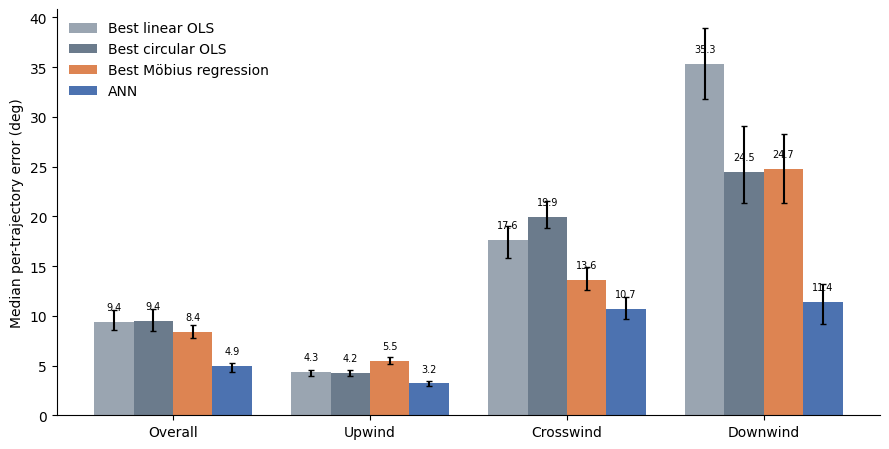

In [18]:
def plot_summary(res_, path, title=None):
    """median per-trajectory error with 95% bootstrap CI: best linear, circular and Möbius baselines and the ANN"""
    fig, ax = plt.subplots(figsize=(9, 4.6))
    groups = ['overall'] + REGIMES
    models = [(BEST['linear'], 'Best linear OLS', '#9aa5b1'), (BEST['circular'], 'Best circular OLS', '#6b7b8c'),
              (BEST['mobius'], 'Best Möbius regression', '#dd8452'), ('ANN', 'ANN', '#4C72B0')]
    w = 0.2
    for i, (key, lab, color) in enumerate(models):
        xs, meds, err = [], [], [[], []]
        for g_i, g in enumerate(groups):
            v = res_[key]['pooled'] if g == 'overall' else res_[key]['by_reg'].query('regime == @g')['err']
            m, lo, hi = bootstrap_ci(v.values)
            xs.append(g_i + (i - 1.5) * w); meds.append(m); err[0].append(m - lo); err[1].append(hi - m)
        ax.bar(xs, meds, width=w, yerr=err, capsize=2, color=color, label=lab if key != 'ANN' else 'ANN')
        for x_, m_ in zip(xs, meds): ax.text(x_, m_ + 1.2, f'{m_:.1f}', ha='center', fontsize=7)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels([g.capitalize() for g in groups])
    ax.set_ylabel('Median per-trajectory error (deg)'); ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False)
    if title: ax.set_title(title, fontsize=10)
    fig.tight_layout()
    fig.savefig(path + '.pdf', bbox_inches='tight')
    fig.savefig(path + '.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_summary(res, '../figures/ann_vs_linear_models_summary')

### Summary

In [19]:
best_base_by_col = {c: min(others, key=lambda k: others[k]['s'][c]) for c in ['overall'] + REGIMES}
print('Median per-trajectory error (deg), ANN vs. the best baseline of any kind in each column:')
for c in ['overall'] + REGIMES:
    k = best_base_by_col[c]; a, b = res['ANN']['s'][c], others[k]['s'][c]
    print(f'  {c:9s} ANN {a:6.2f}   best baseline {b:6.2f} ({k})   ANN is {b / a:4.1f}x lower' if a < b else
          f'  {c:9s} ANN {a:6.2f}   best baseline {b:6.2f} ({k})   baseline is lower')
sig = paired_tbl.groupby('Regime')['ANN better (CI > 0)'].all()
print('\nANN significantly better (paired CI excludes 0) than the best linear, circular and Möbius baselines in:', [r for r in sig.index if sig[r]] or 'none')
print('Not significantly better than at least one of them in:', [r for r in sig.index if not sig[r]] or 'none')

Median per-trajectory error (deg), ANN vs. the best baseline of any kind in each column:
  overall   ANN   4.91   best baseline   8.40 (mobius: air)   ANN is  1.7x lower
  upwind    ANN   3.20   best baseline   3.96 (linear: air+ground)   ANN is  1.2x lower
  crosswind ANN  10.70   best baseline  13.64 (mobius: air)   ANN is  1.3x lower
  downwind  ANN  11.36   best baseline  24.47 (circular: thrust+air+ground)   ANN is  2.2x lower

ANN significantly better (paired CI excludes 0) than the best linear, circular and Möbius baselines in: ['Crosswind', 'Downwind', 'Overall', 'Upwind']
Not significantly better than at least one of them in: none


### Reading the results

- **Single kinematic directions.** Heading is not a function of any single kinematic direction: the best free-slope circular fit captures only part of the variation, and which direction is most informative depends on the regime (Section 1, Table 1).
- **Within-regime fits.** The within-regime Möbius parameters (Section 2) differ from the global ones, so the relationship between kinematics and heading differs between regimes.
- **Pooled vs. per-regime error.** Pooled across all frames, the baselines look respectable because upwind flight dominates the data; their downwind and crosswind errors are several times larger (Tables 1–2).
- **ANN vs. baselines.** The paired comparisons above give, regime by regime, the median per-trajectory difference between each baseline and the ANN, with confidence intervals. The summary cell lists in which regimes the difference is statistically distinguishable from zero; the margin is smallest upwind, where kinematics are most informative.
- **Wind speeds absent from training.** Generalisation to a wind speed absent from training is not guaranteed (Table 4). The baselines are evaluated under the same leave-one-out design and are reported alongside the ANN.

## 5. Evaluated on confident frames only

The summary figure above, scored only on the held-out frames whose heading correction is confident (`heading_confidence > 0.99`, the forward-backward posterior of `heading_correction_viterbi`), where the ground-truth heading is most trustworthy. Nothing is refit: the baselines are the same best linear, circular and Möbius models as above (selected by pooled error on all held-out frames, fit on all training frames), and the ANN is the full-training-set model of `02_training_and_testing_the_ann.ipynb`. Each trajectory's error is the median over its confident frames; trajectories without a confident frame (or without one in a regime) drop out. Saved as `figures/ann_vs_linear_models_summary_conf0.99.{pdf,png}`. (The ANN trained only on confident frames is compared in `07_full_vs_high_confidence_comparison.ipynb`.)

29565 of 36942 held-out frames (80.0 %) have confidence > 0.99, in 945 of 1096 trajectories


Median per-trajectory error (deg), held-out frames with confidence > 0.99:


,Model,n (overall),Overall [95% CI],Upwind [95% CI],Crosswind [95% CI],Downwind [95% CI]
0,linear: thrust+ground,945,"6.76 [6.28, 7.51]","4.06 [3.85, 4.32]","14.36 [13.15, 15.56]","21.44 [18.40, 25.12]"
1,circular: thrust+air+ground,945,"6.95 [6.19, 7.56]","3.95 [3.73, 4.21]","17.89 [16.34, 19.10]","15.86 [13.57, 17.93]"
2,mobius: air,945,"6.78 [6.40, 7.34]","5.25 [4.86, 5.65]","11.92 [10.64, 12.97]","15.70 [13.64, 19.16]"
3,ANN,945,"4.12 [3.83, 4.44]","3.00 [2.80, 3.28]","9.11 [8.05, 9.95]","6.93 [5.84, 8.98]"


trajectories per group: {'overall': 945, 'upwind': 704, 'crosswind': 573, 'downwind': 271}


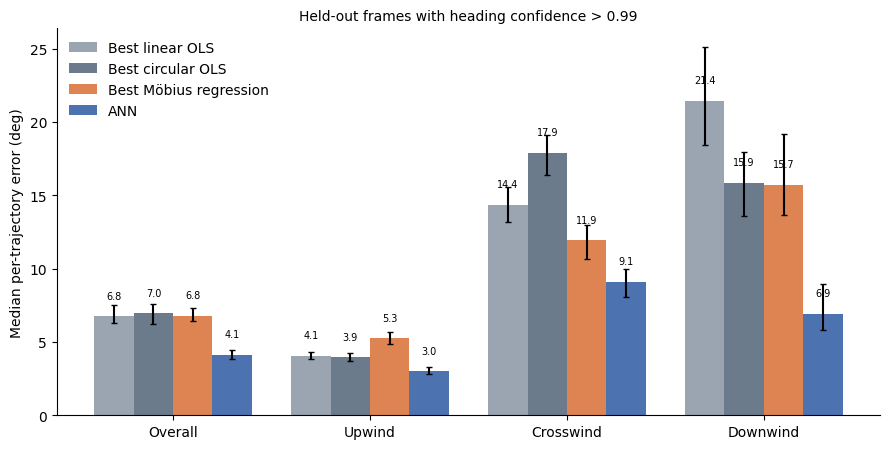

In [20]:
CONF_THRESHOLD = 0.99
conf_mask = (test_df['heading_confidence'] > CONF_THRESHOLD).values
# ann_by_regime.csv has one row per held-out frame in the order of test_df (both follow the data file)
assert len(ann_frames) == len(test_df) and (ann_frames['trajec_objid'].values == test_df['trajec_objid'].values).all()
print(f'{conf_mask.sum()} of {len(test_df)} held-out frames ({100 * conf_mask.mean():.1f} %) have confidence > {CONF_THRESHOLD}, '
      f'in {test_df.loc[conf_mask, "trajec_objid"].nunique()} of {test_df["trajec_objid"].nunique()} trajectories')

res_conf = {}
for key in BEST.values():
    fdf = frame_errors(test_df, fit_predict(train_df, test_df, key))
    res_conf[key] = dict(zip(['s', 'pooled', 'by_reg'], summarize(fdf[conf_mask])))
res_conf['ANN'] = dict(zip(['s', 'pooled', 'by_reg'], summarize(ann_frames[conf_mask])))

rows = []
for key, r in res_conf.items():
    row = {'Model': key, 'n (overall)': len(r['pooled'])}
    for g in ['overall'] + REGIMES:
        v = r['pooled'] if g == 'overall' else r['by_reg'].query('regime == @g')['err']
        row[f'{g.capitalize()} [95% CI]'] = ci_str(*bootstrap_ci(v.values))
    rows.append(row)
print(f'Median per-trajectory error (deg), held-out frames with confidence > {CONF_THRESHOLD}:')
display(pd.DataFrame(rows))
n = {g: len(res_conf['ANN']['pooled']) if g == 'overall' else (res_conf['ANN']['by_reg']['regime'] == g).sum() for g in ['overall'] + REGIMES}
print('trajectories per group:', n)

plot_summary(res_conf, f'../figures/ann_vs_linear_models_summary_conf{CONF_THRESHOLD}',
             title=f'Held-out frames with heading confidence > {CONF_THRESHOLD}')